# Experimento 12 — Eficiência, H2O stacking e TabPFN

22 features (14 do Exp. 11 + 8 de eficiência). Descoberta H2O antes de 2023,
validação expansiva 2023–2025 e seleção por RMSE/LB ponderadas com os mesmos pesos
do Exp. 11. M/W separados, margens brutas e quatro submissions Top1.

[Instalação, metodologia e custo](../../docs/exp12.md). Este notebook inicia os
treinamentos somente quando suas células são executadas. Checkpoints são locais.


In [8]:
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

atual = Path.cwd().resolve()
raiz = next(p for p in [atual, *atual.parents] if (p / 'raw_data').is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src import exp11 as comum
from src import exp12 as exp
from src.exp12_h2o import descobrir_h2o
from src.automl_h2o import inicializar_h2o
from src.efficiency_features import ESTATISTICAS_EFICIENCIA
from src.season_similarity import construir_perfis_temporadas, ranquear_temporadas, ponderar_temporadas
from h2o.exceptions import H2ODependencyWarning
warnings.filterwarnings('ignore', category=H2ODependencyWarning,
    message=r'Converting H2O frame to pandas dataframe using single-thread\.', module=r'h2o\.frame')
comum.configurar_avisos_h2o()

SEED = 42
ANOS = [2023, 2024, 2025]
FEATURES = exp.FEATURES_EFICIENCIA
FEATURES_BASE = exp.FEATURES_BASE
assert len(FEATURES_BASE) == 14 and len(FEATURES) == 22
MAX_MODELS_H2O = 100
MAX_CANDIDATOS_TABPFN = 100
N_FOLDS = 5
LIMITE_BASES_ALLMODELS = 20  # None conserva todas as dependências originais.
ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA = 4 * 3600  # None percorre todo o catálogo.
RODAR_CONTROLE_14_FEATURES = False
EXIGIR_AMBOS_ENSEMBLES = True
REPETIR_FALHAS = False
EXIGIR_GPU = True
N_THREADS = 2
MAX_MEM_SIZE = '4G'
CHECKPOINTS = raiz / 'checkpoints' / 'exp12'
CONJUNTOS = {'eficiencia': FEATURES}
if RODAR_CONTROLE_14_FEATURES:
    CONJUNTOS['baseline'] = FEATURES_BASE
display(comum.versoes())


{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Ambiente e autenticação

Reutiliza `.env.tabpfn` ignorado pelo Git. Não mostra a chave. O H2O usa CPU neste
Windows; TabPFN exige CUDA. A API instalada é verificada antes de gerar o catálogo.


In [9]:
ambiente_tabpfn = comum.detectar_tabpfn(exigir_gpu=EXIGIR_GPU)
comum.carregar_token_tabpfn(raiz / '.env.tabpfn')
display(comum.validar_acesso_tabpfn())
ambiente_h2o = inicializar_h2o(nthreads=N_THREADS, max_mem_size=MAX_MEM_SIZE)
display(ambiente_tabpfn, ambiente_h2o)
comum.salvar_json(CHECKPOINTS / 'ambiente.json', {'tabpfn': ambiente_tabpfn, 'h2o': ambiente_h2o})


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

Cannot build an XGBoost model - no backend found.


{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

{'h2o_version': '3.46.0.12',
 'cluster_version': '3.46.0.12',
 'xgboost_disponivel': False,
 'exclude_algos': ['DeepLearning', 'XGBoost'],
 'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias habilitadas.'}

## Preparação e análise das features

W/L convertidos para cada equipe, usando somente arquivos RegularSeason anteriores
ao limite NCAA de cada ano (2026: DayNum < 134). Histórico M: 2003+, W: 2010+.
Percentuais usam totais sazonais. Poss = FGA − OR + TO + 0.44×FTA.
Ritmo = média por jogo de (Poss próprias + Poss adversárias)/2; sem ajuste por OT.
O fator 0.44 aproxima posses consumidas por lances livres. ORtg/DRtg usam denominadores
próprios/adversários. Denominadores zero causam erro explícito, sem imputação.


,Categoria,JogosTreinoHistorico,PrimeiroAno,UltimoAno,FontesFeatures,Limite2026,SemSobreposicaoNCAA,JogosDetalhados2026,UltimoDayNum2026
0,M,1449,2003,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5647,132
1,W,961,2010,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5479,132


,Categoria,NaN,Inf
SeedDif,M,0,0
WinRateDiff,M,0,0
AvgPointsForDiff,M,0,0
AvgPointsAgainstDiff,M,0,0
OppWinRateDiff,M,0,0
FGPercentageDiff,M,0,0
ThreePointPercentageDiff,M,0,0
FTPercentageDiff,M,0,0
AssistsPerGameDiff,M,0,0
OffensiveReboundsPerGameDiff,M,0,0


,OffensiveRatingDiff,DefensiveRatingDiff,NetRatingDiff,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff
count,1449.000000,1449.000000,1449.000000,1449.000000,1449.000000,1449.000000,1449.000000,1449.000000
mean,0.533818,0.145915,0.387904,0.446373,0.005623,0.002315,0.001232,0.001039
std,7.008187,6.328864,9.580033,4.450222,0.037034,0.022968,0.056693,0.063843
min,-22.420623,-25.090155,-34.428473,-21.620714,-0.143802,-0.074308,-0.184259,-0.245121
25%,-3.863995,-3.738395,-5.675356,-2.470038,-0.018250,-0.013185,-0.036718,-0.039917
50%,0.603862,0.142446,0.358038,0.365345,0.005720,0.002371,0.000089,0.001093
75%,4.958857,4.256384,6.483765,3.333251,0.030823,0.017269,0.038957,0.044323
max,23.028938,19.372793,33.811028,16.856544,0.127030,0.093189,0.192714,0.195232


,SeedDif,WinRateDiff,AvgPointsForDiff,AvgPointsAgainstDiff,OppWinRateDiff,FGPercentageDiff,ThreePointPercentageDiff,FTPercentageDiff,AssistsPerGameDiff,OffensiveReboundsPerGameDiff,...,StealsPerGameDiff,BlocksPerGameDiff,OffensiveRatingDiff,DefensiveRatingDiff,NetRatingDiff,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff
SeedDif,1.000000,-0.608669,-0.427052,0.217111,-0.742324,-0.340285,-0.191874,-0.076926,-0.410900,-0.279415,...,-0.095522,-0.347266,-0.556242,0.411526,-0.678781,-0.089971,-0.301962,0.350869,-0.366112,0.040983
WinRateDiff,-0.608669,1.000000,0.438892,-0.360994,0.094641,0.482469,0.270167,0.077485,0.386396,0.136538,...,0.143575,0.230484,0.634928,-0.577714,0.846131,0.036851,0.459269,-0.329649,0.254523,0.021853
AvgPointsForDiff,-0.427052,0.438892,1.000000,0.549317,0.232142,0.569036,0.373863,0.178940,0.624863,0.337278,...,0.250566,0.223503,0.725973,0.057926,0.492811,0.760145,0.550420,-0.293998,0.277984,0.076645
AvgPointsAgainstDiff,0.217111,-0.360994,0.549317,1.000000,0.001592,0.061339,0.069524,0.105969,0.167516,0.165966,...,0.079755,-0.062679,0.056666,0.742273,-0.448915,0.744790,0.068306,0.059274,-0.023848,0.145249
OppWinRateDiff,-0.742324,0.094641,0.232142,0.001592,1.000000,0.084911,0.021724,0.026166,0.207838,0.260710,...,0.022518,0.291249,0.247804,-0.090127,0.240819,0.096893,0.044957,-0.217984,0.275462,-0.045342
FGPercentageDiff,-0.340285,0.482469,0.569036,0.061339,0.084911,1.000000,0.545447,0.156611,0.585758,-0.221722,...,-0.072567,0.072441,0.719828,-0.051605,0.560675,0.142403,0.909575,-0.020142,0.005528,-0.018862
ThreePointPercentageDiff,-0.191874,0.270167,0.373863,0.069524,0.021724,0.545447,1.000000,0.278848,0.339252,-0.300478,...,-0.170879,-0.098744,0.583889,0.101082,0.360361,-0.005884,0.713082,-0.132919,-0.172057,-0.136518
FTPercentageDiff,-0.076926,0.077485,0.178940,0.105969,0.026166,0.156611,0.278848,1.000000,0.056107,-0.337675,...,-0.193505,-0.199921,0.346838,0.216267,0.110854,-0.064317,0.250113,-0.167904,-0.239307,-0.055094
AssistsPerGameDiff,-0.410900,0.386396,0.624863,0.167516,0.207838,0.585758,0.339252,0.056107,1.000000,0.162324,...,0.141519,0.144531,0.565234,-0.103349,0.481768,0.361825,0.561379,-0.142853,0.209790,-0.218220
OffensiveReboundsPerGameDiff,-0.279415,0.136538,0.337278,0.165966,0.260710,-0.221722,-0.300478,-0.337675,0.162324,1.000000,...,0.309062,0.389443,0.077702,-0.155883,0.159823,0.410204,-0.365606,-0.047163,0.906797,0.133055


,Categoria,NaN,Inf
SeedDif,W,0,0
WinRateDiff,W,0,0
AvgPointsForDiff,W,0,0
AvgPointsAgainstDiff,W,0,0
OppWinRateDiff,W,0,0
FGPercentageDiff,W,0,0
ThreePointPercentageDiff,W,0,0
FTPercentageDiff,W,0,0
AssistsPerGameDiff,W,0,0
OffensiveReboundsPerGameDiff,W,0,0


,OffensiveRatingDiff,DefensiveRatingDiff,NetRatingDiff,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff
count,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000
mean,0.920803,-0.830675,1.751478,0.072513,0.006619,-0.000252,-0.000499,-0.004914
std,10.574278,7.920656,15.084726,4.632650,0.051861,0.026993,0.068148,0.060602
min,-31.690770,-35.076824,-44.402912,-15.380792,-0.143262,-0.092644,-0.246563,-0.252108
25%,-5.904982,-5.967909,-7.481427,-2.875478,-0.028650,-0.018747,-0.044845,-0.046934
50%,0.676103,-0.666045,0.861927,0.243455,0.006781,-0.000523,0.001329,-0.004682
75%,7.404834,4.601879,10.503893,3.145118,0.040550,0.018319,0.043442,0.035285
max,37.370497,23.292219,57.953025,13.465282,0.171675,0.083658,0.236325,0.174817


,SeedDif,WinRateDiff,AvgPointsForDiff,AvgPointsAgainstDiff,OppWinRateDiff,FGPercentageDiff,ThreePointPercentageDiff,FTPercentageDiff,AssistsPerGameDiff,OffensiveReboundsPerGameDiff,...,StealsPerGameDiff,BlocksPerGameDiff,OffensiveRatingDiff,DefensiveRatingDiff,NetRatingDiff,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff
SeedDif,1.000000,-0.539588,-0.606870,0.125907,-0.804324,-0.585991,-0.329231,-0.126271,-0.454081,-0.265423,...,-0.058532,-0.424828,-0.600245,0.337618,-0.598043,-0.260553,-0.473215,0.336266,-0.419545,-0.079153
WinRateDiff,-0.539588,1.000000,0.618024,-0.464855,0.140338,0.654043,0.439917,0.178172,0.544085,0.184916,...,0.136009,0.363375,0.751017,-0.633537,0.859113,0.051858,0.605142,-0.473118,0.391101,0.057263
AvgPointsForDiff,-0.606870,0.618024,1.000000,0.184881,0.372248,0.766504,0.522208,0.349727,0.727152,0.242344,...,0.226291,0.316626,0.862996,-0.201406,0.710708,0.624924,0.740005,-0.498236,0.330096,0.037765
AvgPointsAgainstDiff,0.125907,-0.464855,0.184881,1.000000,0.067943,-0.160366,-0.025872,0.171576,-0.047140,-0.044075,...,-0.063615,-0.276185,-0.160849,0.840523,-0.554094,0.615186,-0.097135,0.125655,-0.279059,0.091317
OppWinRateDiff,-0.804324,0.140338,0.372248,0.067943,1.000000,0.365752,0.165500,0.087948,0.269308,0.178970,...,-0.031224,0.330304,0.320041,-0.073459,0.262918,0.235450,0.256646,-0.148915,0.277985,0.041300
FGPercentageDiff,-0.585991,0.654043,0.766504,-0.160366,0.365752,1.000000,0.640292,0.329035,0.762424,-0.105973,...,0.031082,0.313754,0.873580,-0.314859,0.777699,0.150945,0.929694,-0.291074,0.232803,-0.033359
ThreePointPercentageDiff,-0.329231,0.439917,0.522208,-0.025872,0.165500,0.640292,1.000000,0.354950,0.474579,-0.249806,...,-0.110454,0.123277,0.653704,-0.053423,0.486293,0.016592,0.751322,-0.226606,-0.025529,-0.157798
FTPercentageDiff,-0.126271,0.178172,0.349727,0.171576,0.087948,0.329035,0.354950,1.000000,0.285020,-0.348860,...,-0.160706,-0.054092,0.418774,0.180045,0.199020,0.046052,0.405755,-0.200773,-0.203406,-0.066309
AssistsPerGameDiff,-0.454081,0.544085,0.727152,-0.047140,0.269308,0.762424,0.474579,0.285020,1.000000,-0.005117,...,0.147959,0.265749,0.720885,-0.274754,0.649602,0.304361,0.753801,-0.312660,0.175313,-0.234585
OffensiveReboundsPerGameDiff,-0.265423,0.184916,0.242344,-0.044075,0.178970,-0.105973,-0.249806,-0.348860,-0.005117,1.000000,...,0.332776,0.259142,0.065915,-0.301924,0.204739,0.369019,-0.278289,-0.091750,0.874916,0.158040


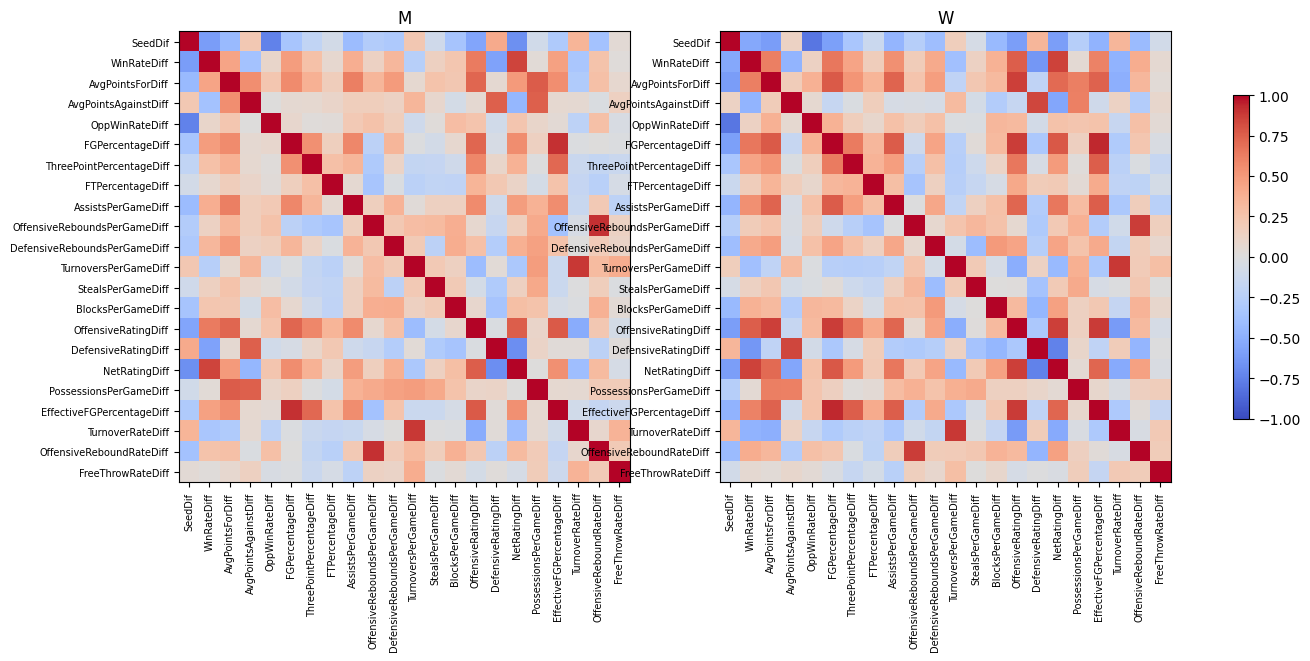

In [10]:
preparacao = exp.preparar_dados(raiz / 'raw_data')
jogos = preparacao['jogos']
confrontos, sample = preparacao['confrontos'], preparacao['sample']
DADOS_CONJUNTOS = {'eficiencia': jogos}
if RODAR_CONTROLE_14_FEATURES:
    controle = {cat: tabela.drop(columns=[n + 'Diff' for n in ESTATISTICAS_EFICIENCIA]).copy()
                for cat, tabela in jogos.items()}
    exp.validar_controle(jogos, controle)
    DADOS_CONJUNTOS['baseline'] = controle
display(preparacao['auditoria'])
for cat, tabela in jogos.items():
    display(pd.DataFrame({'Categoria': cat, 'NaN': tabela[FEATURES].isna().sum(),
        'Inf': np.isinf(tabela[FEATURES].to_numpy()).sum(axis=0)}, index=FEATURES))
    display(tabela[[n + 'Diff' for n in ESTATISTICAS_EFICIENCIA]].describe())
    display(tabela[FEATURES].corr())
    assert tabela.TeamA.lt(tabela.TeamB).all()
    np.testing.assert_allclose(tabela.Target, tabela.ScoreA - tabela.ScoreB)
    np.testing.assert_allclose(tabela.NetRatingDiff, tabela.OffensiveRatingDiff - tabela.DefensiveRatingDiff)
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (cat, tabela) in zip(axes, jogos.items()):
    matriz = tabela[FEATURES].corr()
    im = ax.imshow(matriz, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=range(22), yticks=range(22), xticklabels=FEATURES, yticklabels=FEATURES, title=cat)
    ax.tick_params(axis='x', labelrotation=90, labelsize=7)
    ax.tick_params(axis='y', labelsize=7)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.6)
plt.show()


## Similaridade fixa

Mantemos o perfil original de 52 dimensões. Nenhuma feature de eficiência é
adicionada à distância. Padronização somente nos anos anteriores a 2026;
pesos inversos às distâncias de 2023–2025, iguais em todas as comparações.


In [11]:
perfis = construir_perfis_temporadas(preparacao['dados'], preparacao['limites'])
similaridade = ranquear_temporadas(perfis['perfis'], 2026, ANOS)
REFERENCIAS = ponderar_temporadas(similaridade['ranking'], n_referencias=3)
assert len(perfis['perfis'].columns) == 53
assert max(similaridade['anos_padronizacao']) < 2026
np.testing.assert_allclose(REFERENCIAS.Peso.sum(), 1.)
display(REFERENCIAS)
comum.salvar_json(CHECKPOINTS / 'similaridade.json', {
    'referencias': REFERENCIAS.to_dict('records'), 'anos_padronizacao': similaridade['anos_padronizacao'],
    'normalizacao': similaridade['normalizacao'].to_dict('records')})


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


## TabPFN — catálogo e pilotos leve/pesado

Até 100 configurações/categoria: 2 versões × 5 n_estimators (4–64) × 5 perfis × 2
temperaturas. Perfis: padrão, transformação do alvo identidade/safepower e shift
de colunas rotate/nenhum. Todas usam seed 42; nenhuma repetição só para aumentar
o número. Mudanças do alvo são aprendidas apenas no treino pelo TabPFN.
Não usamos subsampling ou ignore_pretraining_limits=True.

Pilotos fixos por categoria/conjunto: Fast/4 e 3.5/64, perfil padrão, temperatura 1,
corte 2023. Executados sequencialmente e reutilizados na avaliação.


In [12]:
catalogo_tabpfn = [c for cat in ['M', 'W'] for c in exp.candidatos_tabpfn(cat,
    device=ambiente_tabpfn['device'], max_candidatos=MAX_CANDIDATOS_TABPFN, seed=SEED)]
display(pd.DataFrame(catalogo_tabpfn))
pilotos = {}
estimativas = []
for conjunto, features in CONJUNTOS.items():
    pilotos[conjunto] = exp.pilotos_tabpfn(DADOS_CONJUNTOS[conjunto], catalogo_tabpfn, features=features,
        pasta=CHECKPOINTS / conjunto / 'avaliacao')
    display(pd.DataFrame([{k: r.get(k) for k in ['Categoria', 'Candidato', 'Familia', 'status', 'erro', 'recursos']}
        for r in pilotos[conjunto]]))
    for cat in ['M', 'W']:
        referencias_tempo = {}
        for r in pilotos[conjunto]:
            if r['Categoria'] == cat and r['status'] == 'ok':
                p = r['config']['candidato']['Parametros']
                referencias_tempo[p['version']] = r['recursos']['segundos'] / p['n_estimators']
        estimativa = sum(3 * c['Parametros']['n_estimators'] * referencias_tempo[c['Familia']]
            for c in catalogo_tabpfn if c['Categoria'] == cat) if len(referencias_tempo) == 2 else None
        estimativas.append({'Conjunto': conjunto, 'Categoria': cat,
            'HorasTabPFNEstimadas': None if estimativa is None else estimativa/3600,
            'Regra': 'linear em n_estimators; custo dos outros perfis/anos pode variar'})
display(pd.DataFrame(estimativas))
comum.salvar_json(CHECKPOINTS / 'pilotos.json', {'pilotos': pilotos, 'estimativas': estimativas})


,Candidato,Categoria,Abordagem,Familia,Parametros,Perfil,Estrutura,SeedRepeticao
0,M_tabpfn12_2973465e4981a4f7,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",padrao,ad8e41eeb296be27,42
1,M_tabpfn12_53e56db25f2544e6,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",padrao,ef8247b5688fef1f,42
2,M_tabpfn12_33d31c0be877a927,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_identidade,960a8ef006d98cf2,42
3,M_tabpfn12_34cc6a16be684582,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_identidade,5be28ba835394e5d,42
4,M_tabpfn12_2c5a2f66d71abdc7,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_safepower,870febc0987e74d1,42
...,...,...,...,...,...,...,...,...
195,W_tabpfn12_dca0267e0adceea1,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando...",alvo_safepower,5f1e709e380fd51a,42
196,W_tabpfn12_9b930594f0e2a382,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando...",colunas_rotate,2d7a2e4ee3dafa19,42
197,W_tabpfn12_6955b0f184868879,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando...",colunas_rotate,5c12a0e66041c2e3,42
198,W_tabpfn12_40450405c352c05b,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando...",colunas_sem_shift,dd3471c8dbf62892,42


,Categoria,Candidato,Familia,status,erro,recursos
0,M,M_tabpfn12_2973465e4981a4f7,V3_5_FAST,ok,None,"{'rss_pico_mb': 2379.7578125, 'cuda_pico_mb': ..."
1,M,M_tabpfn12_f4076c2240d6e3c6,V3_5,ok,None,"{'rss_pico_mb': 3545.03125, 'cuda_pico_mb': 46..."
2,W,W_tabpfn12_2973465e4981a4f7,V3_5_FAST,ok,None,"{'rss_pico_mb': 3311.2734375, 'cuda_pico_mb': ..."
3,W,W_tabpfn12_f4076c2240d6e3c6,V3_5,ok,None,"{'rss_pico_mb': 3558.34765625, 'cuda_pico_mb':..."


,Conjunto,Categoria,HorasTabPFNEstimadas,Regra
0,eficiencia,M,0.619035,linear em n_estimators; custo dos outros perfi...
1,eficiencia,W,0.254171,linear em n_estimators; custo dos outros perfi...


## Descoberta H2O e receitas de stacking

Uma busca por categoria/conjunto, somente Season < 2023, max_models=100 e cinco
folds internos por temporada. Todos os modelos-base elegíveis participam da
validação externa. Snapshots são salvos antes da extração.

Para cada tipo, escolhemos a composição do melhor ensemble pré-2023 por RMSE
interno. Receita equivalente documentada: GLM não negativo sem regularização
como metalearner fixo, sem afirmar identidade com o AutoML. AllModels usa até
LIMITE_BASES_ALLMODELS bases da composição original por RMSE interno.
As bases são retreinadas com folds idênticos e previsões OOF preservadas.
Nenhuma temporada externa entra no stacking. Bases OOF são compartilhadas na sessão.


In [13]:
descobertas, catalogos = {}, {}
for conjunto, features in CONJUNTOS.items():
    descobertas[conjunto] = {}
    catalogos[conjunto] = list(catalogo_tabpfn)
    for cat in ['M', 'W']:
        d = descobrir_h2o(DADOS_CONJUNTOS[conjunto][cat], cat, features=features, pasta=CHECKPOINTS / conjunto / 'descoberta',
            max_models=MAX_MODELS_H2O, seed=SEED, n_folds=N_FOLDS,
            limite_all=LIMITE_BASES_ALLMODELS, exclude_algos=ambiente_h2o['exclude_algos'])
        descobertas[conjunto][cat] = d
        catalogos[conjunto].extend(d['candidatos'])
        display(pd.DataFrame(d['falhas']))
        display(pd.DataFrame(d['ensembles_originais']))
        stacks = [c for c in d['candidatos'] if c['Familia'].startswith('StackedEnsemble_')]
        display(pd.DataFrame(stacks))
        if EXIGIR_AMBOS_ENSEMBLES:
            assert {c['Familia'] for c in stacks} == {'StackedEnsemble_BestOfFamily', 'StackedEnsemble_AllModels'}, 'Confira as limitações de dependências/ensembles acima antes de continuar.'
    display(pd.DataFrame(catalogos[conjunto]))
    display(pd.DataFrame(catalogos[conjunto]).groupby(['Categoria', 'Abordagem', 'Familia']).size().rename('Candidatos'))


""


,ModeloOrigem,RMSEInterno,BasesOriginais,MetalearnerOrigem,AlgoritmoMetalearnerOrigem,ParametrosMetalearnerOrigem
0,StackedEnsemble_BestOfFamily_1_AutoML_1_202611...,11.344830,"[GLM_1_AutoML_1_20261103_163759, GBM_grid_1_Au...",metalearner_AUTO_StackedEnsemble_BestOfFamily_...,glm,{'model_id': 'metalearner_AUTO_StackedEnsemble...
1,StackedEnsemble_AllModels_1_AutoML_1_20261103_...,11.376699,"[GLM_1_AutoML_1_20261103_163759, GBM_grid_1_Au...",metalearner_AUTO_StackedEnsemble_AllModels_1_A...,glm,{'model_id': 'metalearner_AUTO_StackedEnsemble...


,Candidato,Categoria,Abordagem,Familia,Parametros,RMSEInterno,ModeloOrigem,OrigemEnsemble,BasesAntesDoLimite,BasesExcluidasPeloLimite
0,M_stack_BestOfFamily_3c8d1fae695eb07b,M,h2o,StackedEnsemble_BestOfFamily,"{'Bases': ['M_h2o_0c6c991e59254b1a', 'M_h2o_ab...",11.344830,StackedEnsemble_BestOfFamily_1_AutoML_1_202611...,{'ModeloOrigem': 'StackedEnsemble_BestOfFamily...,"[M_h2o_0c6c991e59254b1a, M_h2o_ab487be0e86b80e...",[]
1,M_stack_AllModels_e131d28a175eeea9,M,h2o,StackedEnsemble_AllModels,"{'Bases': ['M_h2o_0c6c991e59254b1a', 'M_h2o_ab...",11.376699,StackedEnsemble_AllModels_1_AutoML_1_20261103_...,{'ModeloOrigem': 'StackedEnsemble_AllModels_1_...,"[M_h2o_0c6c991e59254b1a, M_h2o_ab487be0e86b80e...","[M_h2o_607b29b970b1f545, M_h2o_50e7b1c2e4a1462..."


""


,ModeloOrigem,RMSEInterno,BasesOriginais,MetalearnerOrigem,AlgoritmoMetalearnerOrigem,ParametrosMetalearnerOrigem
0,StackedEnsemble_BestOfFamily_1_AutoML_2_202611...,12.331289,"[GLM_1_AutoML_2_20261103_163906, GBM_grid_1_Au...",metalearner_AUTO_StackedEnsemble_BestOfFamily_...,glm,{'model_id': 'metalearner_AUTO_StackedEnsemble...
1,StackedEnsemble_AllModels_1_AutoML_2_20261103_...,12.449266,"[GLM_1_AutoML_2_20261103_163906, GBM_grid_1_Au...",metalearner_AUTO_StackedEnsemble_AllModels_1_A...,glm,{'model_id': 'metalearner_AUTO_StackedEnsemble...


,Candidato,Categoria,Abordagem,Familia,Parametros,RMSEInterno,ModeloOrigem,OrigemEnsemble,BasesAntesDoLimite,BasesExcluidasPeloLimite
0,W_stack_BestOfFamily_dde758149487bfe9,W,h2o,StackedEnsemble_BestOfFamily,"{'Bases': ['W_h2o_2f1eaf68e91ceb17', 'W_h2o_0c...",12.331289,StackedEnsemble_BestOfFamily_1_AutoML_2_202611...,{'ModeloOrigem': 'StackedEnsemble_BestOfFamily...,"[W_h2o_2f1eaf68e91ceb17, W_h2o_0ca85cb4a76a709...",[]
1,W_stack_AllModels_4e2af0b87a6035bf,W,h2o,StackedEnsemble_AllModels,"{'Bases': ['W_h2o_2f1eaf68e91ceb17', 'W_h2o_0c...",12.449266,StackedEnsemble_AllModels_1_AutoML_2_20261103_...,{'ModeloOrigem': 'StackedEnsemble_AllModels_1_...,"[W_h2o_2f1eaf68e91ceb17, W_h2o_0ca85cb4a76a709...","[W_h2o_42e94fae4cd9b904, W_h2o_0ed40a9d424acbe..."


,Candidato,Categoria,Abordagem,Familia,Parametros,Perfil,Estrutura,SeedRepeticao,ParametrosOriginais,ParametrosNulosOmitidos,AjustesReconstrucao,ModeloOrigem,PosicaoLeaderboard,RMSEInterno,OrigemEnsemble,BasesAntesDoLimite,BasesExcluidasPeloLimite
0,M_tabpfn12_2973465e4981a4f7,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",padrao,ad8e41eeb296be27,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,M_tabpfn12_53e56db25f2544e6,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",padrao,ef8247b5688fef1f,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,M_tabpfn12_33d31c0be877a927,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_identidade,960a8ef006d98cf2,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,M_tabpfn12_34cc6a16be684582,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_identidade,5be28ba835394e5d,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,M_tabpfn12_2c5a2f66d71abdc7,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r...",alvo_safepower,870febc0987e74d1,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,W_h2o_a9e3f4dc4e7dfd47,W,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",NaN,NaN,NaN,{'model_id': 'GBM_grid_1_AutoML_2_20261103_163...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_2_20261103_163906_model_62,108.0,13.723463,NaN,NaN,NaN
416,W_h2o_ae57beb2638a9941,W,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",NaN,NaN,NaN,{'model_id': 'GBM_grid_1_AutoML_2_20261103_163...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_2_20261103_163906_model_30,109.0,13.930996,NaN,NaN,NaN
417,W_h2o_5545479b9b529767,W,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",NaN,NaN,NaN,{'model_id': 'GBM_grid_1_AutoML_2_20261103_163...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_2_20261103_163906_model_109,110.0,15.987203,NaN,NaN,NaN
418,W_stack_BestOfFamily_dde758149487bfe9,W,h2o,StackedEnsemble_BestOfFamily,"{'Bases': ['W_h2o_2f1eaf68e91ceb17', 'W_h2o_0c...",NaN,NaN,NaN,NaN,NaN,NaN,StackedEnsemble_BestOfFamily_1_AutoML_2_202611...,NaN,12.331289,{'ModeloOrigem': 'StackedEnsemble_BestOfFamily...,"[W_h2o_2f1eaf68e91ceb17, W_h2o_0ca85cb4a76a709...",[]


Categoria  Abordagem  Familia                     
M          h2o        StackedEnsemble_AllModels         1
                      StackedEnsemble_BestOfFamily      1
                      drf                               2
                      gbm                             105
                      glm                               1
           tabpfn     V3_5                             50
                      V3_5_FAST                        50
W          h2o        StackedEnsemble_AllModels         1
                      StackedEnsemble_BestOfFamily      1
                      drf                               2
                      gbm                             105
                      glm                               1
           tabpfn     V3_5                             50
                      V3_5_FAST                        50
Name: Candidatos, dtype: int64

## Auditoria da origem dos modelos — sem repetir a busca

`max_models=100` é repassado ao H2OAutoML nativo, sem modeling_plan ou cotas manuais.
Nos checkpoints inspecionados, cada categoria tem **100 GBMs do grid + 5 GBMs
iniciais + DRF + XRT + GLM = 108 bases**, todas no leaderboard original, mais dois
Stacked Ensembles. O motor excedeu em oito o limite solicitado; não truncamos
esses candidatos válidos. O motivo interno exato exige logs de execução; não
atribuímos esse excedente a paralelismo ou a bases adicionadas pelo nosso código.

A tabela abaixo separa origem nativa, dependências auxiliares, metalearners e
candidatos únicos. Reajustes das mesmas bases e modelos dos folds não são novas
configurações do catálogo. As duas receitas de stacking e suas dependências são
preservadas. A célula apenas recarrega os módulos e audita os resultados existentes.


In [14]:
import importlib
import src.exp12_h2o as modulo_h2o12
importlib.reload(modulo_h2o12)
importlib.reload(exp)
descobrir_h2o = modulo_h2o12.descobrir_h2o
auditorias_origens = []
for conjunto, grupo in descobertas.items():
    for cat, descoberta in grupo.items():
        auditoria = modulo_h2o12.auditar_descoberta(descoberta)
        auditorias_origens.append({'Conjunto': conjunto, 'Categoria': cat, **auditoria['resumo']})
        print(conjunto, cat, auditoria['nota'])
        display(pd.DataFrame(auditoria['familias_por_origem']))
resumo_origens = pd.DataFrame(auditorias_origens).set_index(['Conjunto', 'Categoria'])
display(resumo_origens.T)

for conjunto, features in CONJUNTOS.items():
    print('Avaliações efetivamente salvas:', conjunto)
    display(exp.auditar_checkpoints(DADOS_CONJUNTOS[conjunto], catalogos[conjunto],
        features=features, pasta=CHECKPOINTS / conjunto / 'avaliacao', n_folds=N_FOLDS, seed=SEED))


eficiencia M O leaderboard nativo excedeu o max_models solicitado. Os modelos excedentes vieram do AutoML, não da reconstrução; nenhum candidato foi removido.


,Origem,Etapa,Familia,Quantidade
0,AutoML: Stacked Ensemble,stacking,stackedensemble,2
1,AutoML: modelo-base,grid,gbm,100
2,AutoML: modelo-base,inicial/outros,drf,2
3,AutoML: modelo-base,inicial/outros,gbm,5
4,AutoML: modelo-base,inicial/outros,glm,1


eficiencia W O leaderboard nativo excedeu o max_models solicitado. Os modelos excedentes vieram do AutoML, não da reconstrução; nenhum candidato foi removido.


,Origem,Etapa,Familia,Quantidade
0,AutoML: Stacked Ensemble,stacking,stackedensemble,2
1,AutoML: modelo-base,grid,gbm,100
2,AutoML: modelo-base,inicial/outros,drf,2
3,AutoML: modelo-base,inicial/outros,gbm,5
4,AutoML: modelo-base,inicial/outros,glm,1


Conjunto                                                                             eficiencia  \
Categoria                                                                                     M   
max_models_solicitado                                                                       100   
linhas_leaderboard                                                                          110   
modelos_base_automl                                                                         108   
ensembles_automl                                                                              2   
excedente_base_sobre_max_models                                                               8   
ids_leaderboard_repetidos                                                                     0   
ids_snapshots_repetidos                                                                       0   
snapshots_fora_leaderboard                                                                   []   
bases_auxiliares_fora_leaderboard                                                            []   
quantidade_bases_auxiliares_fora_leaderboard                                                  0   
metalearners_originais_fora_leaderboard       [metalearner_AUTO_StackedEnsemble_AllModels_1_...   
bases_unicas_elegiveis                                                                      108   
receitas_ensemble_avaliacao                                                                   2   
bases_reutilizadas_pelas_receitas                                                            21   
ajustes_cv_auxiliares_planejados_por_corte                                                  105   
metalearners_receitas_planejados_por_corte                                                    2   
candidatos_unicos_avaliacao_externa                                                         110   
ids_candidatos_repetidos                                                                      0   

Conjunto                                                                                         
Categoria                                                                                     W  
max_models_solicitado                                                                       100  
linhas_leaderboard                                                                          110  
modelos_base_automl                                                                         108  
ensembles_automl                                                                              2  
excedente_base_sobre_max_models                                                               8  
ids_leaderboard_repetidos                                                                     0  
ids_snapshots_repetidos                                                                       0  
snapshots_fora_leaderboard                                                                   []  
bases_auxiliares_fora_leaderboard                                                            []  
quantidade_bases_auxiliares_fora_leaderboard                                                  0  
metalearners_originais_fora_leaderboard       [metalearner_AUTO_StackedEnsemble_AllModels_1_...  
bases_unicas_elegiveis                                                                      108  
receitas_ensemble_avaliacao                                                                   2  
bases_reutilizadas_pelas_receitas                                                            22  
ajustes_cv_auxiliares_planejados_por_corte                                                  110  
metalearners_receitas_planejados_por_corte                                                    2  
candidatos_unicos_avaliacao_externa                                                         110  
ids_candidatos_repetidos                                                                      0

Avaliações efetivamente salvas: eficiencia


,Categoria,Abordagem,CandidatosNoCatalogo,CandidatosComCortesRegistrados,CandidatosComTresCortesValidos,BasesComTresCortesValidos,EnsemblesComTresCortesValidos,CortesValidos,CortesComFalha
0,M,h2o,110,110,110,108,2,330,0
1,M,tabpfn,100,52,50,50,0,152,0
2,W,h2o,110,0,0,0,0,0,0
3,W,tabpfn,100,2,0,0,0,2,0


## Validação temporal

Configurações fixas, treino Season < ano e avaliação em ano. Cada candidato precisa
dos três cortes válidos; falhas não geram médias parciais. Orçamento TabPFN é
verificado entre candidatos completos e inclui tempos dos checkpoints. Pode ser
ultrapassado por um candidato; não é timeout rígido. Pendentes são registrados.
O treino final fica fora do orçamento da busca.

H2O reutiliza as bases necessárias ao stacking no mesmo corte. Essas bases fazem
cinco folds internos, mesmo quando avaliadas individualmente; as demais dispensam
CV no reajuste. Auditamos o mapa de folds e os anos do metalearner.


In [15]:
resultados = {}
for conjunto, features in CONJUNTOS.items():
    if conjunto == 'baseline':
        exp.validar_controle(jogos, DADOS_CONJUNTOS[conjunto])
    avaliacao = exp.avaliar_banco(DADOS_CONJUNTOS[conjunto], catalogos[conjunto], features=features,
        pasta=CHECKPOINTS / conjunto / 'avaliacao', n_folds=N_FOLDS, seed=SEED,
        orcamento_tabpfn_por_categoria=ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA,
        repetir_falhas=REPETIR_FALHAS)
    scores, ranking = comum.rankings(avaliacao['avaliacoes'], REFERENCIAS)
    resultados[conjunto] = {'avaliacao': avaliacao, 'scores': scores,
        'ranking': ranking, 'candidatos': catalogos[conjunto]}
    display(pd.DataFrame([{k: r.get(k) for k in ['Categoria', 'Abordagem', 'Familia', 'Candidato', 'Season', 'status', 'RMSE', 'LB', 'SegundosTreino', 'SegundosInferencia', 'recursos', 'erro']}
        for r in avaliacao['avaliacoes']]))
    display(scores, ranking)
    print(conjunto, 'pendentes:', avaliacao['pendentes'])
    comum.salvar_json(CHECKPOINTS / conjunto / 'rankings.json', {
        'scores': scores.to_dict('records'), 'ranking': ranking.to_dict('records')})


TabPFN/M: M_tabpfn12_2973465e4981a4f7 registrado.
TabPFN/M: M_tabpfn12_53e56db25f2544e6 registrado.
TabPFN/M: M_tabpfn12_33d31c0be877a927 registrado.
TabPFN/M: M_tabpfn12_34cc6a16be684582 registrado.
TabPFN/M: M_tabpfn12_2c5a2f66d71abdc7 registrado.
TabPFN/M: M_tabpfn12_95beaf425161d405 registrado.
TabPFN/M: M_tabpfn12_2ccb9a971c426ab1 registrado.
TabPFN/M: M_tabpfn12_8766363716aa1313 registrado.
TabPFN/M: M_tabpfn12_7c8a0580fab71131 registrado.
TabPFN/M: M_tabpfn12_90729dade6f72bfe registrado.
TabPFN/M: M_tabpfn12_9d0ebfa70f4dee59 registrado.
TabPFN/M: M_tabpfn12_8e7fba8b158096f7 registrado.
TabPFN/M: M_tabpfn12_5a771e6f02aacf60 registrado.
TabPFN/M: M_tabpfn12_31dc1e9d61399623 registrado.
TabPFN/M: M_tabpfn12_d1eec64c5c3daa7d registrado.
TabPFN/M: M_tabpfn12_193a5f1fc6b02274 registrado.
TabPFN/M: M_tabpfn12_66abb88e8a794c6e registrado.
TabPFN/M: M_tabpfn12_25bcb8c52bdfc098 registrado.
TabPFN/M: M_tabpfn12_2f47f428bc93c998 registrado.
TabPFN/M: M_tabpfn12_206269e1a0777906 registrado.


,Categoria,Abordagem,Familia,Candidato,Season,status,RMSE,LB,SegundosTreino,SegundosInferencia,recursos,erro
0,M,h2o,glm,M_h2o_0c6c991e59254b1a,2023,ok,12.372704,0.090484,0.249487,0.251638,"{'rss_pico_mb': 3293.05078125, 'jvm_heap_obser...",None
1,M,h2o,gbm,M_h2o_ab487be0e86b80ec,2023,ok,12.037087,0.082394,0.434497,0.249759,"{'rss_pico_mb': 3291.25, 'jvm_heap_observado_m...",None
2,M,h2o,gbm,M_h2o_5eb6e9d905cc8d68,2023,ok,12.097723,0.084111,0.427333,0.250205,"{'rss_pico_mb': 3291.578125, 'jvm_heap_observa...",None
3,M,h2o,gbm,M_h2o_5909c78566707e22,2023,ok,12.120886,0.087176,0.425374,0.245535,"{'rss_pico_mb': 3291.31640625, 'jvm_heap_obser...",None
4,M,h2o,gbm,M_h2o_0ec9f93125b10153,2023,ok,12.366039,0.083830,0.218508,0.241219,"{'rss_pico_mb': 3291.35546875, 'jvm_heap_obser...",None
...,...,...,...,...,...,...,...,...,...,...,...,...
1255,W,tabpfn,V3_5,W_tabpfn12_40450405c352c05b,2024,ok,10.331078,0.043000,0.638374,4.970843,"{'rss_pico_mb': 2647.71875, 'cuda_pico_mb': 59...",None
1256,W,tabpfn,V3_5,W_tabpfn12_40450405c352c05b,2025,ok,14.433879,0.044820,0.655799,5.334927,"{'rss_pico_mb': 2650.109375, 'cuda_pico_mb': 5...",None
1257,W,tabpfn,V3_5,W_tabpfn12_bbf163bacb28bfc4,2023,ok,12.272419,0.066200,0.544638,4.691332,"{'rss_pico_mb': 2646.2421875, 'cuda_pico_mb': ...",None
1258,W,tabpfn,V3_5,W_tabpfn12_bbf163bacb28bfc4,2024,ok,10.323359,0.041925,0.653640,5.052422,"{'rss_pico_mb': 2639.58984375, 'cuda_pico_mb':...",None


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025
0,M,h2o,M_h2o_00767ac1ffc6b6aa,12.602678,12.371552,13.520103,11.919556,0.078447,0.089327,0.081917,0.067186
1,M,h2o,M_h2o_02910426eda382fe,12.535825,12.027920,13.579027,11.940016,0.073992,0.081015,0.080943,0.062337
2,M,h2o,M_h2o_0509cc915a9aed9f,12.676756,12.839123,13.412427,11.872241,0.081687,0.099317,0.080720,0.069571
3,M,h2o,M_h2o_09af85b4d9867b49,12.295607,11.868682,13.274402,11.699943,0.073366,0.081971,0.078431,0.062300
4,M,h2o,M_h2o_09ccc9842c545c1b,12.786167,13.236764,13.776452,11.531886,0.085174,0.108147,0.089917,0.063796
...,...,...,...,...,...,...,...,...,...,...,...
415,W,tabpfn,W_tabpfn12_e5ca5d3fef7485fb,12.397297,12.291647,10.314284,14.413796,0.050283,0.067408,0.043174,0.044254
416,W,tabpfn,W_tabpfn12_e6097820cde29070,12.497608,12.355408,10.277299,14.668866,0.050666,0.066735,0.042258,0.046626
417,W,tabpfn,W_tabpfn12_f19209e33d0dd91e,12.473767,12.337566,10.282101,14.613942,0.050182,0.066633,0.042067,0.045587
418,W,tabpfn,W_tabpfn12_f20bbe99d76118a5,12.373219,12.341563,10.262881,14.360516,0.049900,0.067663,0.042641,0.043540


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,Metrica,Posicao
0,M,h2o,M_h2o_6868c1ea9159ac75,12.101766,11.827025,13.204862,11.278061,0.069981,0.081719,0.075874,0.055830,rmse,1
1,M,h2o,M_h2o_c0081fade8d8497a,12.160571,12.433709,12.864047,11.304229,0.073526,0.092575,0.073566,0.059425,rmse,2
2,M,h2o,M_h2o_1d1bd60f01ab0f7a,12.162055,11.944327,13.141915,11.410940,0.071516,0.082171,0.075585,0.059861,rmse,3
3,M,h2o,M_h2o_4975cc975a607a4d,12.168508,12.124335,13.205235,11.236325,0.071227,0.085889,0.074180,0.057654,rmse,4
4,M,h2o,M_stack_AllModels_e131d28a175eeea9,12.178699,12.307233,13.055409,11.267910,0.073721,0.089022,0.076499,0.059838,rmse,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
835,W,tabpfn,W_tabpfn12_31dc1e9d61399623,12.494634,12.375161,10.258482,14.663854,0.050761,0.066911,0.042109,0.046888,lb,96
836,W,tabpfn,W_tabpfn12_5cbbc6f4ddfc3e35,12.496957,12.376858,10.271735,14.656470,0.050790,0.066891,0.042389,0.046721,lb,97
837,W,tabpfn,W_tabpfn12_5fb94a5abf593ea8,12.426339,12.314026,10.337467,14.453213,0.050803,0.067774,0.043627,0.044950,lb,98
838,W,tabpfn,W_tabpfn12_5a771e6f02aacf60,12.419903,12.325560,10.304651,14.458057,0.050847,0.067957,0.043310,0.045229,lb,99


eficiencia pendentes: []


## Comparações controladas e modelos-base × ensembles

Controle opcional usa exatamente os mesmos jogos, anos, seed, budgets e espaços
TabPFN, com nova descoberta H2O de 100 modelos nas 14 features. Configurações
H2O podem mudar como consequência das features. Quantidades efetivas e falhas
precisam ser consideradas se os orçamentos não permitirem concluir ambos.
O controle não gera submissions.


,Conjunto,Categoria,Abordagem,Metrica,Candidato,Familia,RMSE_pond,LB_pond
0,eficiencia,M,h2o,rmse,M_h2o_6868c1ea9159ac75,gbm,12.101766,0.069981
110,eficiencia,W,h2o,rmse,W_stack_AllModels_4e2af0b87a6035bf,StackedEnsemble_AllModels,12.385079,0.050634
220,eficiencia,M,tabpfn,rmse,M_tabpfn12_b80535f142f7499f,V3_5_FAST,12.113226,0.074158
320,eficiencia,W,tabpfn,rmse,W_tabpfn12_95d63295f213febc,V3_5_FAST,12.358049,0.049786
420,eficiencia,M,h2o,lb,M_h2o_6868c1ea9159ac75,gbm,12.101766,0.069981
530,eficiencia,W,h2o,lb,W_h2o_ab850c5472223432,gbm,12.567658,0.049971
640,eficiencia,M,tabpfn,lb,M_tabpfn12_5ceb9f85742f38b5,V3_5,12.277730,0.071850
740,eficiencia,W,tabpfn,lb,W_tabpfn12_2ccb9a971c426ab1,V3_5_FAST,12.363499,0.049610


,Conjunto,Categoria,Metrica,StackedEnsemble,Candidato,RMSE_pond,LB_pond
0,eficiencia,M,lb,False,M_h2o_6868c1ea9159ac75,12.101766,0.069981
1,eficiencia,M,lb,True,M_stack_AllModels_e131d28a175eeea9,12.178699,0.073721
2,eficiencia,M,rmse,False,M_h2o_6868c1ea9159ac75,12.101766,0.069981
3,eficiencia,M,rmse,True,M_stack_AllModels_e131d28a175eeea9,12.178699,0.073721
4,eficiencia,W,lb,False,W_h2o_ab850c5472223432,12.567658,0.049971
5,eficiencia,W,lb,True,W_stack_AllModels_4e2af0b87a6035bf,12.385079,0.050634
6,eficiencia,W,rmse,False,W_h2o_2f1eaf68e91ceb17,12.393064,0.050730
7,eficiencia,W,rmse,True,W_stack_AllModels_4e2af0b87a6035bf,12.385079,0.050634


Metrica                                                  lb  \
Conjunto   Categoria Abordagem                                
eficiencia M         h2o             M_h2o_6868c1ea9159ac75   
                     tabpfn     M_tabpfn12_5ceb9f85742f38b5   
           W         h2o             W_h2o_ab850c5472223432   
                     tabpfn     W_tabpfn12_2ccb9a971c426ab1   

Metrica                                                       rmse  \
Conjunto   Categoria Abordagem                                       
eficiencia M         h2o                    M_h2o_6868c1ea9159ac75   
                     tabpfn            M_tabpfn12_b80535f142f7499f   
           W         h2o        W_stack_AllModels_4e2af0b87a6035bf   
                     tabpfn            W_tabpfn12_95d63295f213febc   

Metrica                         MesmoModelo  
Conjunto   Categoria Abordagem               
eficiencia M         h2o               True  
                     tabpfn           False  
           W         h2o              False  
                     tabpfn           False

Segundos  Cortes
Conjunto   Categoria Abordagem                    
eficiencia M         h2o        173.195437     330
                     tabpfn     889.049320     300
           W         h2o        175.826843     330
                     tabpfn     650.617039     300

,Conjunto,Categoria,Abordagem,Candidato,Segundos
0,eficiencia,M,h2o,M_h2o_00767ac1ffc6b6aa,1.386416
1,eficiencia,M,h2o,M_h2o_02910426eda382fe,1.412568
2,eficiencia,M,h2o,M_h2o_0509cc915a9aed9f,1.375069
3,eficiencia,M,h2o,M_h2o_09af85b4d9867b49,1.381876
4,eficiencia,M,h2o,M_h2o_09ccc9842c545c1b,4.980501
...,...,...,...,...,...
415,eficiencia,W,tabpfn,W_tabpfn12_e5ca5d3fef7485fb,9.491380
416,eficiencia,W,tabpfn,W_tabpfn12_e6097820cde29070,16.491497
417,eficiencia,W,tabpfn,W_tabpfn12_f19209e33d0dd91e,17.281821
418,eficiencia,W,tabpfn,W_tabpfn12_f20bbe99d76118a5,6.392619


,Conjunto,Categoria,SegundosDescoberta
0,eficiencia,M,66.964774
1,eficiencia,W,57.821212


Controle 14 features desabilitado: não atribuir diferenças ao efeito isolado das novas features.


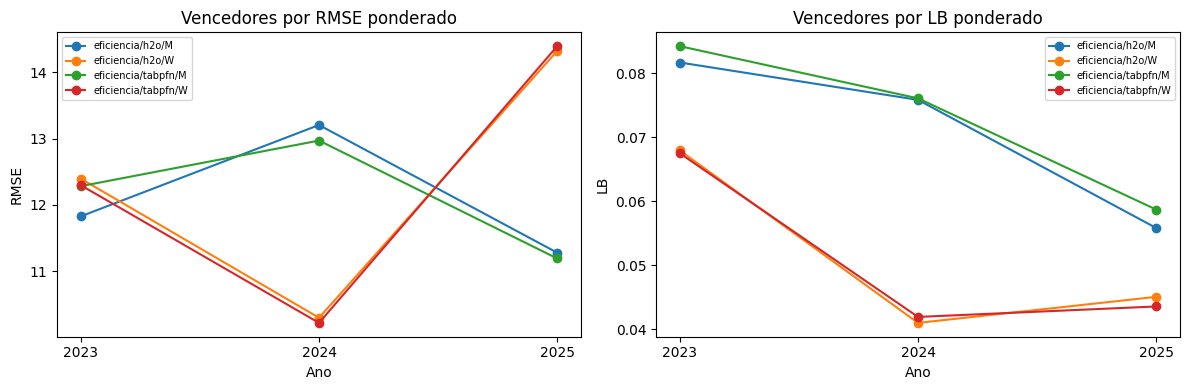

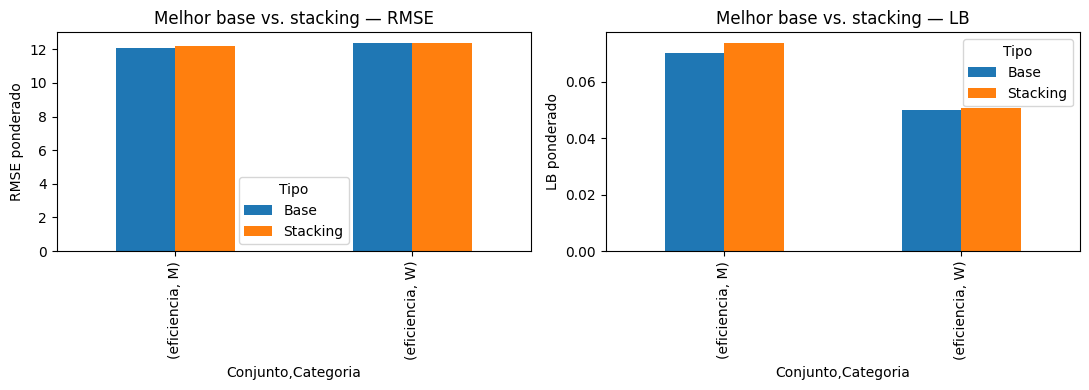

In [16]:
comparacao = exp.comparar_rankings(resultados)
melhores = comparacao.loc[comparacao.Posicao.eq(1)]
display(melhores[['Conjunto', 'Categoria', 'Abordagem', 'Metrica', 'Candidato', 'Familia', 'RMSE_pond', 'LB_pond']])
h2o_familias = comparacao.loc[comparacao.Abordagem.eq('h2o')].sort_values('Posicao').groupby(
    ['Conjunto', 'Categoria', 'Metrica', 'StackedEnsemble'], as_index=False).first()
display(h2o_familias[['Conjunto', 'Categoria', 'Metrica', 'StackedEnsemble', 'Candidato', 'RMSE_pond', 'LB_pond']])
escolhas = melhores.pivot(index=['Conjunto', 'Categoria', 'Abordagem'], columns='Metrica', values='Candidato')
escolhas['MesmoModelo'] = escolhas.rmse.eq(escolhas.lb)
display(escolhas)
tempos = pd.DataFrame([{'Conjunto': conjunto, 'Categoria': r['Categoria'], 'Abordagem': r['Abordagem'],
    'Candidato': r['Candidato'], 'Segundos': r['recursos'].get('segundos', 0), 'Status': r['status']}
    for conjunto, resultado in resultados.items() for r in resultado['avaliacao']['avaliacoes']])
display(tempos.groupby(['Conjunto', 'Categoria', 'Abordagem']).agg(Segundos=('Segundos', 'sum'), Cortes=('Status', 'size')))
display(tempos.groupby(['Conjunto', 'Categoria', 'Abordagem', 'Candidato']).Segundos.sum().reset_index())
display(pd.DataFrame([{'Conjunto': conjunto, 'Categoria': cat, 'SegundosDescoberta': d['segundos']}
    for conjunto, grupo in descobertas.items() for cat, d in grupo.items()]))
if RODAR_CONTROLE_14_FEATURES:
    display(melhores.pivot(index=['Categoria', 'Abordagem', 'Metrica'], columns='Conjunto', values=['RMSE_pond', 'LB_pond']))
else:
    print('Controle 14 features desabilitado: não atribuir diferenças ao efeito isolado das novas features.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axes, ['RMSE', 'LB']):
    for _, row in melhores.loc[melhores.Metrica.eq(metrica.lower())].iterrows():
        ax.plot(ANOS, [row[f'{metrica}_{ano}'] for ano in ANOS], marker='o',
            label=f'{row.Conjunto}/{row.Abordagem}/{row.Categoria}')
    ax.set(title=f'Vencedores por {metrica} ponderado', xlabel='Ano', ylabel=metrica, xticks=ANOS)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(axes, ['RMSE', 'LB']):
    selecionados = h2o_familias.loc[h2o_familias.Metrica.eq(metrica.lower())].copy()
    selecionados['Tipo'] = np.where(selecionados.StackedEnsemble, 'Stacking', 'Base')
    selecionados.pivot(index=['Conjunto', 'Categoria'], columns='Tipo', values=metrica + '_pond').plot.bar(ax=ax)
    ax.set(title=f'Melhor base vs. stacking — {metrica}', ylabel=metrica + ' ponderado')
plt.tight_layout()
plt.show()


## Exp. 11 × Exp. 12

Lemos somente os resultados anteriores, sem alterá-los. Recalculamos seus rankings
nos mesmos anos e pesos atuais antes de comparar. O Exp. 12 amplia simultaneamente
features e busca; essa comparação não identifica sozinha a causa de uma melhoria.
O score histórico de seleção não é um teste independente.


In [17]:
arquivo_exp11 = raiz / 'checkpoints' / 'exp11' / 'rankings.json'
if arquivo_exp11.exists():
    antigo = json.loads(arquivo_exp11.read_text(encoding='utf-8'))
    anuais = []
    for row in antigo['scores']:
        for ano in ANOS:
            anuais.append({k: row[k] for k in ['Categoria', 'Abordagem', 'Candidato']} |
                {'Season': ano, 'status': 'ok', 'RMSE': row[f'RMSE_{ano}'], 'LB': row[f'LB_{ano}']})
    _, ranking11 = comum.rankings(anuais, REFERENCIAS)
    melhores11 = ranking11.loc[ranking11.Posicao.eq(1)].assign(Experimento='Exp. 11')
    melhores12 = melhores.loc[melhores.Conjunto.eq('eficiencia')].assign(Experimento='Exp. 12')
    display(pd.concat([melhores11, melhores12], ignore_index=True)[
        ['Experimento', 'Categoria', 'Abordagem', 'Metrica', 'Candidato', 'RMSE_pond', 'LB_pond']])
else:
    print('Checkpoint do Exp. 11 não encontrado: comparação anterior indisponível.')


,Experimento,Categoria,Abordagem,Metrica,Candidato,RMSE_pond,LB_pond
0,Exp. 11,M,h2o,rmse,M_h2o_afec215223f32962,12.265886,0.075573
1,Exp. 11,W,h2o,rmse,W_h2o_f915b2ce8c23549e,12.381923,0.050443
2,Exp. 11,M,tabpfn,rmse,M_tabpfn_V3_5_FAST_4,12.124692,0.073912
3,Exp. 11,W,tabpfn,rmse,W_tabpfn_V3_5_32,12.448118,0.049810
4,Exp. 11,M,h2o,lb,M_h2o_a5fb385a7ba264e4,12.327752,0.071406
5,Exp. 11,W,h2o,lb,W_h2o_f915b2ce8c23549e,12.381923,0.050443
6,Exp. 11,M,tabpfn,lb,M_tabpfn_V3_5_4,12.171589,0.073222
7,Exp. 11,W,tabpfn,lb,W_tabpfn_V3_5_32,12.448118,0.049810
8,Exp. 12,M,h2o,rmse,M_h2o_6868c1ea9159ac75,12.101766,0.069981
9,Exp. 12,W,h2o,rmse,W_stack_AllModels_4e2af0b87a6035bf,12.385079,0.050634


## Reajuste até 2025 e quatro submissions

Somente vencedores Top1 das 22 features. Ensembles são reconstruídos com OOF do
histórico permitido; M/W separados e configurações vencedoras únicas reutilizadas.
CSV usa margem bruta, sem sigmoid; pares sem duas seeds recebem 0.
IDs, ordem, linhas, finitude e duplicidade de previsões são conferidos.


In [18]:
principal = resultados['eficiencia']
top1 = principal['ranking'].loc[principal['ranking'].Posicao.eq(1)]
assert len(top1) == 8, 'Faltam vencedores em alguma abordagem/categoria: consulte falhas e pendentes.'
display(top1)
submissions = exp.gerar_submissions(jogos, principal['candidatos'], principal['ranking'], confrontos, sample,
    features=FEATURES, pasta=CHECKPOINTS / 'eficiencia' / 'final', destino=raiz / 'submissions',
    n_folds=N_FOLDS, seed=SEED)
assert len(submissions['submissions']) == 4
display(pd.DataFrame(submissions['submissions']), pd.DataFrame(submissions['tempos_finais']))


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,Metrica,Posicao
0,M,h2o,M_h2o_6868c1ea9159ac75,12.101766,11.827025,13.204862,11.278061,0.069981,0.081719,0.075874,0.055830,rmse,1
110,W,h2o,W_stack_AllModels_4e2af0b87a6035bf,12.385079,12.395060,10.296088,14.321765,0.050634,0.069792,0.042445,0.044110,rmse,1
220,M,tabpfn,M_tabpfn12_b80535f142f7499f,12.113226,12.282151,12.970052,11.191120,0.074158,0.088620,0.078066,0.059843,rmse,1
320,W,tabpfn,W_tabpfn12_95d63295f213febc,12.358049,12.295960,10.219091,14.394449,0.049786,0.067274,0.042059,0.044065,rmse,1
420,M,h2o,M_h2o_6868c1ea9159ac75,12.101766,11.827025,13.204862,11.278061,0.069981,0.081719,0.075874,0.055830,lb,1
530,W,h2o,W_h2o_ab850c5472223432,12.567658,11.792220,10.359950,15.194747,0.049971,0.067954,0.040984,0.045056,lb,1
640,M,tabpfn,M_tabpfn12_5ceb9f85742f38b5,12.277730,12.134165,13.263666,11.466201,0.071850,0.084275,0.076112,0.058710,lb,1
740,W,tabpfn,W_tabpfn12_2ccb9a971c426ab1,12.363499,12.331574,10.240548,14.362733,0.049610,0.067513,0.041915,0.043553,lb,1


,Arquivo,Abordagem,Metrica,ModeloM,ModeloW,Linhas,IdenticaA
0,submission_exp12_h2o_lb_top1_2026.csv,h2o,lb,M_h2o_6868c1ea9159ac75,W_h2o_ab850c5472223432,132133,None
1,submission_exp12_h2o_rmse_top1_2026.csv,h2o,rmse,M_h2o_6868c1ea9159ac75,W_stack_AllModels_4e2af0b87a6035bf,132133,None
2,submission_exp12_tabpfn_lb_top1_2026.csv,tabpfn,lb,M_tabpfn12_5ceb9f85742f38b5,W_tabpfn12_2ccb9a971c426ab1,132133,None
3,submission_exp12_tabpfn_rmse_top1_2026.csv,tabpfn,rmse,M_tabpfn12_b80535f142f7499f,W_tabpfn12_95d63295f213febc,132133,None


,Candidato,Segundos
0,M_h2o_6868c1ea9159ac75,0.717947
1,M_tabpfn12_b80535f142f7499f,3.037490
2,M_tabpfn12_5ceb9f85742f38b5,18.614494
3,W_stack_AllModels_4e2af0b87a6035bf,9.682230
4,W_h2o_ab850c5472223432,0.717551
5,W_tabpfn12_95d63295f213febc,2.415847
6,W_tabpfn12_2ccb9a971c426ab1,1.241982


## Registro e resultados Kaggle

Referência Exp. 8: **0.04783**. Kaggle não participa da escolha das configurações.
Preencha aqui os quatro resultados após submeter; não há resultados inventados.


In [19]:
registro = {'features': FEATURES, 'features_base': FEATURES_BASE, 'seed': SEED, 'anos': ANOS,
    'pesos': REFERENCIAS.to_dict('records'), 'versoes': comum.versoes(),
    'max_models_h2o': MAX_MODELS_H2O, 'max_candidatos_tabpfn': MAX_CANDIDATOS_TABPFN,
    'n_folds': N_FOLDS, 'limite_allmodels': LIMITE_BASES_ALLMODELS,
    'orcamento_tabpfn': ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA,
    'controle_14_features': RODAR_CONTROLE_14_FEATURES,
    'auditoria_dados': preparacao['auditoria'].to_dict('records'),
    'submissions': submissions}
comum.salvar_json(CHECKPOINTS / 'registro.json', registro)
display(registro)


{'features': ['SeedDif',
  'WinRateDiff',
  'AvgPointsForDiff',
  'AvgPointsAgainstDiff',
  'OppWinRateDiff',
  'FGPercentageDiff',
  'ThreePointPercentageDiff',
  'FTPercentageDiff',
  'AssistsPerGameDiff',
  'OffensiveReboundsPerGameDiff',
  'DefensiveReboundsPerGameDiff',
  'TurnoversPerGameDiff',
  'StealsPerGameDiff',
  'BlocksPerGameDiff',
  'OffensiveRatingDiff',
  'DefensiveRatingDiff',
  'NetRatingDiff',
  'PossessionsPerGameDiff',
  'EffectiveFGPercentageDiff',
  'TurnoverRateDiff',
  'OffensiveReboundRateDiff',
  'FreeThrowRateDiff'],
 'features_base': ['SeedDif',
  'WinRateDiff',
  'AvgPointsForDiff',
  'AvgPointsAgainstDiff',
  'OppWinRateDiff',
  'FGPercentageDiff',
  'ThreePointPercentageDiff',
  'FTPercentageDiff',
  'AssistsPerGameDiff',
  'OffensiveReboundsPerGameDiff',
  'DefensiveReboundsPerGameDiff',
  'TurnoversPerGameDiff',
  'StealsPerGameDiff',
  'BlocksPerGameDiff'],
 'seed': 42,
 'anos': [2023, 2024, 2025],
 'pesos': [{'Season': 2025,
   'Distancia': 7.624698